In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

In [3]:
films = pd.read_csv("movies.csv",sep=",")
notes = pd.read_csv("ratings.csv",sep=",")
tags = pd.read_csv("tags.csv",sep=",")

In [4]:
print(films.shape)
films.head()

(9742, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


#### On a un total de 9742 films qui sont répertoriés

#### Plusieurs films ont plusieurs genres à la fois. On met ces genres sous forme de liste dans les colonnes et on va les séparer avec explode pour pouvoir voir combien de fois un genre est répété. 

genre_list
Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
Name: count, dtype: int64


<Axes: ylabel='genre_list'>

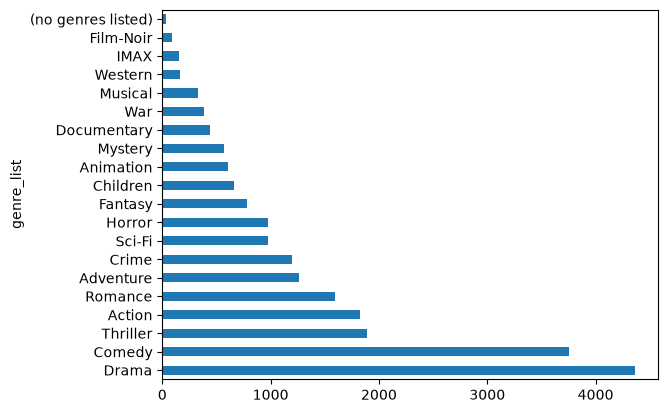

In [5]:
films["genre_list"] = films["genres"].str.split("|")
genre_counts = films.explode("genre_list")["genre_list"].value_counts()

print(genre_counts)
genre_counts.plot(kind="barh")

#### Les genres les plus représentés sont _Drama, Comedy, Thriller, Action, Romance, Adventure, Crime_. Ils pourront servir de base pour notre démarrage à froid.

#### Là on va effectuer des statistiques sur les notes des utilisateurs pour chaque type de genre.

In [6]:
movie_genres = films[["movieId", "genre_list"]].explode("genre_list")
df = notes.merge(movie_genres, on="movieId", how="left")

genre_stats = (
    df.groupby("genre_list")["rating"]
      .agg(nb_notes="count", note_moyenne="mean")
      .sort_values("nb_notes", ascending=False)
)
print(genre_stats)

                    nb_notes  note_moyenne
genre_list                                
Drama                  41928      3.656184
Comedy                 39053      3.384721
Action                 30635      3.447984
Thriller               26452      3.493706
Adventure              24161      3.508609
Romance                18124      3.506511
Sci-Fi                 17243      3.455721
Crime                  16681      3.658294
Fantasy                11834      3.491001
Children                9208      3.412956
Mystery                 7674      3.632460
Horror                  7291      3.258195
Animation               6988      3.629937
War                     4859      3.808294
IMAX                    4145      3.618335
Musical                 4138      3.563678
Western                 1930      3.583938
Documentary             1219      3.797785
Film-Noir                870      3.920115
(no genres listed)        47      3.489362


#### Les notes moyennes ne sont pas très significatives. Elles ne varient que de quelques dixièmes. En plus on a pas le même nombre de votes pour chaque genres. On ne peut pas dire que le genre _Film-noir_ est le plus aimé avec une moyenne de 3.920115 alors qu'il n'y a que 870 votes. Tandis que d'autres films ont près de 41000 votes. 

In [7]:
comparaison = pd.DataFrame({
    "part_films": genre_counts / genre_counts.sum(),
    "part_notes": genre_stats["nb_notes"] / genre_stats["nb_notes"].sum(),
})
comparaison["ratio"] = comparaison["part_notes"] / comparaison["part_films"]
print(comparaison.sort_values("ratio", ascending=False))

                    part_films  part_notes     ratio
genre_list                                          
IMAX                  0.007155    0.015101  2.110739
Adventure             0.057191    0.088025  1.539142
Sci-Fi                0.044376    0.062821  1.415643
Action                0.082775    0.111611  1.348369
Fantasy               0.035274    0.043114  1.222253
Thriller              0.085763    0.096371  1.123688
Crime                 0.054293    0.060773  1.119360
Children              0.030067    0.033547  1.115743
Mystery               0.025946    0.027958  1.077542
War                   0.017298    0.017703  1.023412
Musical               0.015124    0.015076  0.996807
Western               0.007562    0.007031  0.929839
Animation             0.027667    0.025459  0.920193
Romance               0.072270    0.066030  0.913668
Comedy                0.170078    0.142280  0.836558
Film-Noir             0.003940    0.003170  0.804576
Drama                 0.197473    0.152754  0.

Le ratio compare la part des notes reçues par un genre à sa part dans le catalogue.
Il mesure le niveau d'attention que reçoit un genre, pas son appréciation.

- Ratio > 1 : genre sur-noté par rapport à sa présence dans le catalogue (films plus consommés que la moyenne).
- Ratio < 1 : genre sous-noté par rapport à sa présence (films moins consommés, genre de niche).
- Ratio ≈ 1 : attention proportionnelle à la présence dans le catalogue.

L'appréciation d'un genre se lit sur sa note moyenne, à comparer au ratio.
Un ratio élevé indique un biais de popularité au niveau du genre : le modèle aura
plus de données sur ces genres et risque de les recommander davantage.

In [8]:
print(notes.shape)
notes.head()

(100836, 4)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


#### Là on a un total de 100836 notes attribuées aux films

In [9]:
notes["timestamp"] = pd.to_datetime(notes["timestamp"],unit="s")
notes.head(2)

,userId,movieId,rating,timestamp
0,1,1,4.0,2000-07-30 18:45:03
1,1,3,4.0,2000-07-30 18:20:47


In [10]:
## On peut regrouper par films et caculer des metriques dessus

stat_note = notes.groupby("movieId")["rating"].agg(
    note_moyenne="mean",
    nb_votes="count").merge(films[["movieId","title"]], on="movieId")
stat_note.head()


,movieId,note_moyenne,nb_votes,title
0,1,3.920930,215,Toy Story (1995)
1,2,3.431818,110,Jumanji (1995)
2,3,3.259615,52,Grumpier Old Men (1995)
3,4,2.357143,7,Waiting to Exhale (1995)
4,5,3.071429,49,Father of the Bride Part II (1995)


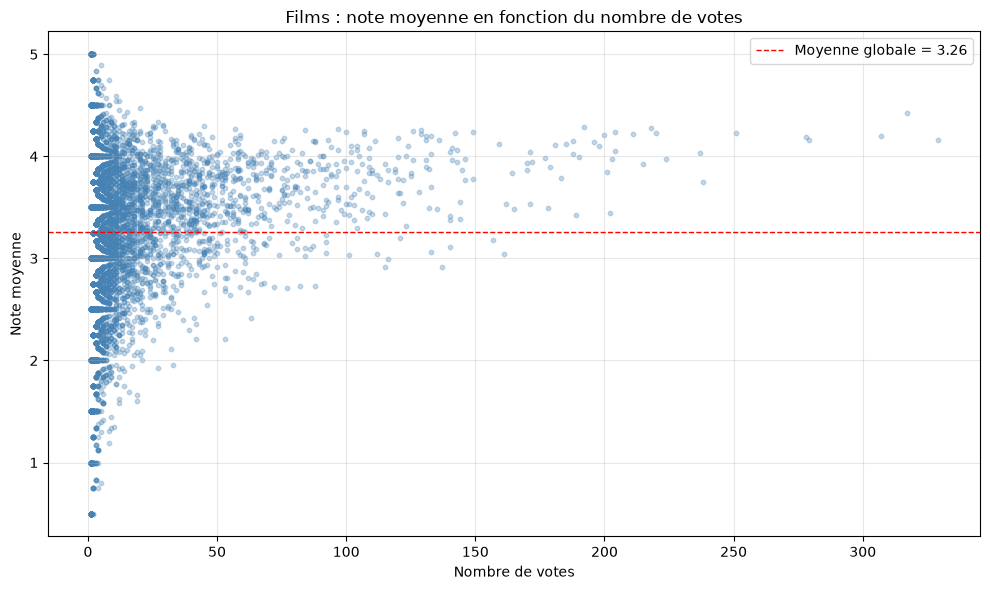

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    stat_note["nb_votes"], stat_note["note_moyenne"],
    alpha=0.3, s=10, color="steelblue",
)

ax.set_xlabel("Nombre de votes")
ax.set_ylabel("Note moyenne")
ax.set_title("Films : note moyenne en fonction du nombre de votes")
ax.grid(alpha=0.3)
ax.axhline(stat_note["note_moyenne"].mean(), color="red", ls="--", lw=1,
           label=f"Moyenne globale = {stat_note['note_moyenne'].mean():.2f}")
ax.legend()

plt.tight_layout()
plt.show()

### Interprétation : note moyenne en fonction du nombre de votes

**Observations**

1. **Forme en entonnoir.** Pour les films avec très peu de votes (moins de 10), la note moyenne varie de 0,5 à 5. Cette dispersion vient de la taille de l'échantillon : avec 1 ou 2 votes, la moyenne reflète l'avis d'une seule personne. Plus le nombre de votes augmente, plus la dispersion diminue et la moyenne se stabilise.

2. **Relation positive entre popularité et note.** Au-delà de 100 votes, presque tous les films ont une note moyenne supérieure à la moyenne globale (3,26), entre 3,5 et 4,3. Les films très notés sont donc aussi ceux qui sont le mieux notés.

3. **Concentration des films à gauche.** La grande majorité des films ont peu de votes (longue traîne) : [X %] des films ont moins de 10 votes.

**Interprétation**

- Les moyennes élevées observées sur les films à 1 ou 2 votes ne sont pas fiables. Un classement par note moyenne brute placerait en tête des films peu connus, sans valeur statistique.
- La relation popularité-note traduit un **biais de sélection** : les utilisateurs notent surtout les films qu'ils ont choisi de voir, et donc qu'ils s'attendent à apprécier. Un modèle apprendra que « populaire » signifie « bien noté », ce qui renforce le biais de popularité.

**Décisions pour l'implémentation**

- Ne pas utiliser la moyenne brute pour classer les films : utiliser une **moyenne régularisée (bayésienne)** qui ramène vers la moyenne globale les films peu notés.
- Définir un **seuil minimal de votes** pour l'évaluation, et traiter les films en dessous comme des cas de **cold start** (repli sur les genres ou les tags).
- **Régulariser** le modèle (factorisation matricielle) pour limiter le surapprentissage sur les films peu notés.
- Évaluer les performances **par tranche de popularité**, pas seulement en global.

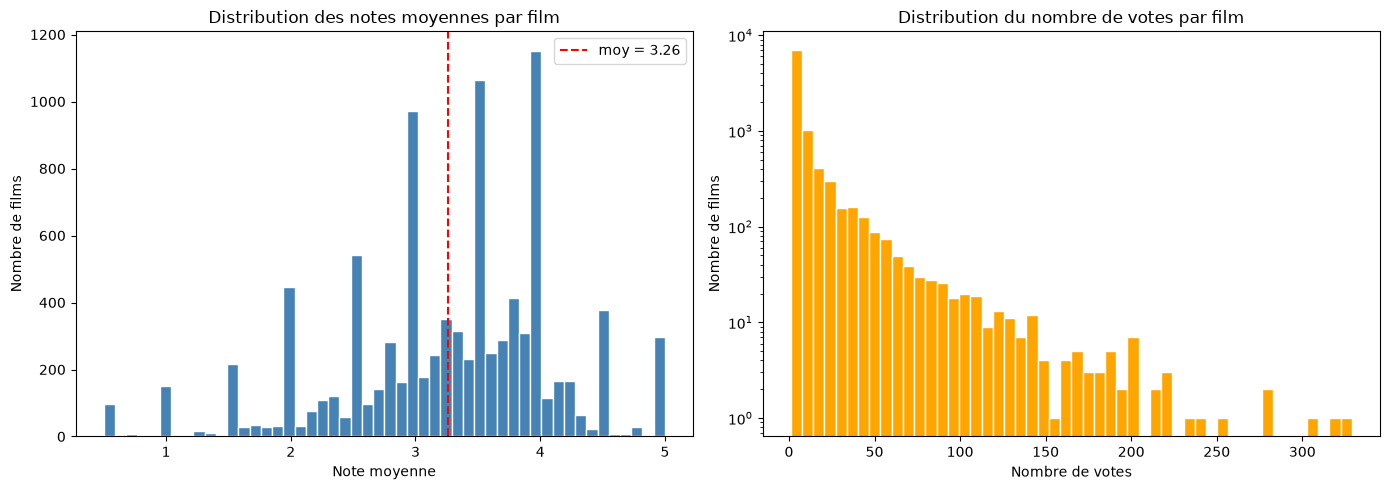

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- distribution des notes moyennes ---
axes[0].hist(stat_note["note_moyenne"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_xlabel("Note moyenne")
axes[0].set_ylabel("Nombre de films")
axes[0].set_title("Distribution des notes moyennes par film")
axes[0].axvline(stat_note["note_moyenne"].mean(), color="red", ls="--",
                label=f"moy = {stat_note['note_moyenne'].mean():.2f}")
axes[0].legend()

# --- distribution du nombre de votes (échelle log car très asymétrique) ---
axes[1].hist(stat_note["nb_votes"], bins=50, color="orange", edgecolor="white")
axes[1].set_xlabel("Nombre de votes")
axes[1].set_ylabel("Nombre de films")
axes[1].set_title("Distribution du nombre de votes par film")
axes[1].set_yscale("log")   # ← indispensable : sinon tout écrasé à gauche

plt.tight_layout()
plt.show()

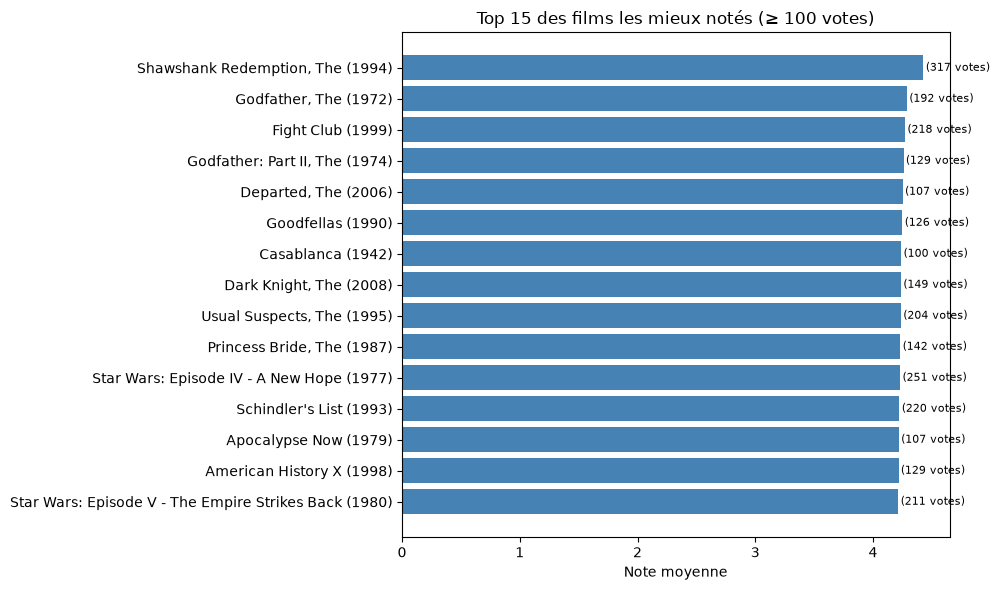

In [13]:
# --- filtre : au moins 100 votes pour être fiable ---
top = (
    stat_note.query("nb_votes >= 100")
         .sort_values("note_moyenne", ascending=False)
         .head(15)
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["title"], top["note_moyenne"], color="steelblue")
ax.invert_yaxis()                       # meilleur en haut
ax.set_xlabel("Note moyenne")
ax.set_title("Top 15 des films les mieux notés (≥ 100 votes)")

# afficher le nb de votes à droite de chaque barre
for i, (note, n) in enumerate(zip(top["note_moyenne"], top["nb_votes"])):
    ax.text(note + 0.02, i, f"({n} votes)", va="center", fontsize=8)

plt.tight_layout()
plt.show()

#### La premiere approche serait de faire une recommandation basée sur l'audience d'un film. C'est a dire on recommande les films qui sont les plus appréciés des utilisateurs. Mais la il faudrait définir une métrique qui prenne en compte, et la note moyenne obtenue par le film, et le nombre de vote obtenu par le film. On utilise une moyenne de note pondérée inspirée de IMDb

$$ WR = \frac{v}{v+m}R+ \frac{m}{v+m}C $$

#### R: Note moyenne du film
#### v: Nombre de notes du film
#### m: Nombre minimal de notes choisi
#### C: Moyenne générale de toutes les notes

In [14]:
movie_stats = notes.groupby("movieId").agg(
    average_rating=("rating", "mean"),
    rating_count=("rating", "count")
).reset_index()

print(movie_stats.head())

   movieId  average_rating  rating_count
0        1        3.920930           215
1        2        3.431818           110
2        3        3.259615            52
3        4        2.357143             7
4        5        3.071429            49


In [30]:
C = notes["rating"].mean()

print("Moyenne générale :", C)

Moyenne générale : 3.501556983616962


In [31]:
m = 10

movie_stats["weighted_rating"] = (
    (movie_stats["rating_count"] /
     (movie_stats["rating_count"] + m))
    * movie_stats["average_rating"]
    +
    (m /
     (movie_stats["rating_count"] + m))
    * C
)

In [33]:
recommendations = movie_stats.merge(
    films[["movieId", "title", "genres"]],
    on="movieId",
    how="left"
)

recommendations = recommendations.sort_values(
    by="weighted_rating",
    ascending=False
)

print(
    recommendations[
        ["title", "average_rating", "rating_count", "weighted_rating"]
    ].head(5)
)

                                 title  average_rating  rating_count  \
277   Shawshank Redemption, The (1994)        4.429022           317   
659              Godfather, The (1972)        4.289062           192   
2224                 Fight Club (1999)        4.272936           218   
921     Godfather: Part II, The (1974)        4.259690           129   
46          Usual Suspects, The (1995)        4.237745           204   

      weighted_rating  
277          4.400659  
659          4.250077  
2224         4.239103  
921          4.205148  
46           4.203344  


In [34]:
def popularity_recommender(ratings, movies,m = 100, n=10):

    C = ratings["rating"].mean()
    

    stats = ratings.groupby("movieId").agg(
        average_rating=("rating", "mean"),
        rating_count=("rating", "count")
    ).reset_index()

    stats["score"] = (
        (stats["rating_count"] / (stats["rating_count"] + m))
        * stats["average_rating"]
        +
        (m / (stats["rating_count"] + m)) * C
    )

    result = stats.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId"
    )

    return result.sort_values(
        "score", ascending=False
    ).head(n)

In [35]:
top_movies = popularity_recommender(
    notes,
    films,
    n=10
)

print(top_movies[["title", "genres", "score"]])

                                          title                       genres  \
277            Shawshank Redemption, The (1994)                  Crime|Drama   
2224                          Fight Club (1999)  Action|Crime|Drama|Thriller   
257                         Pulp Fiction (1994)  Comedy|Crime|Drama|Thriller   
224   Star Wars: Episode IV - A New Hope (1977)      Action|Adventure|Sci-Fi   
659                       Godfather, The (1972)                  Crime|Drama   
314                         Forrest Gump (1994)     Comedy|Drama|Romance|War   
1938                         Matrix, The (1999)       Action|Sci-Fi|Thriller   
461                     Schindler's List (1993)                    Drama|War   
46                   Usual Suspects, The (1995)       Crime|Mystery|Thriller   
510            Silence of the Lambs, The (1991)        Crime|Horror|Thriller   

         score  
277   4.206608  
2224  4.030364  
257   4.026181  
224   4.023236  
659   4.019369  
314   4.009687  


In [15]:
print(tags.shape)
tags.head()

(3683, 4)


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


In [16]:
tags["tag"] = tags["tag"].astype(str).str.lower().str.strip()
tags = tags.drop_duplicates(subset=["userId", "movieId", "tag"])

In [17]:
n_movies = films["movieId"].nunique()
n_tagged = tags["movieId"].nunique()
print(f"Films avec au moins un tag : {n_tagged / n_movies:.0%}")
print(f"Nombre total de tags : {len(tags)}, tags distincts : {tags['tag'].nunique()}")

Films avec au moins un tag : 16%
Nombre total de tags : 3683, tags distincts : 1475


In [18]:
tag_counts = tags["tag"].value_counts()
print(tag_counts.head(20))

# Combien de tags n'apparaissent qu'une seule fois ?
print(f"Tags utilisés une seule fois : {(tag_counts == 1).mean():.0%}")

tag
in netflix queue      131
atmospheric            41
funny                  24
superhero              24
surreal                24
thought-provoking      24
sci-fi                 23
disney                 23
quirky                 22
religion               22
dark comedy            21
suspense               21
psychology             21
twist ending           20
visually appealing     20
comedy                 19
politics               19
crime                  19
music                  17
dark                   16
Name: count, dtype: int64
Tags utilisés une seule fois : 63%


In [19]:
movie_rating = notes.groupby("movieId")["rating"].agg(note_moyenne="mean", nb_notes="count")

tm = tags[["movieId", "tag"]].drop_duplicates().merge(movie_rating, on="movieId")

tag_stats = (
    tm.groupby("tag")
      .agg(nb_films=("movieId", "nunique"), note_moyenne=("note_moyenne", "mean"))
      .query("nb_films >= 20")   # ignore les tags trop rares
      .sort_values("note_moyenne")
)
print(tag_stats.head(10))   # tags associés aux films les moins bien notés
print(tag_stats.tail(10))   # tags associés aux films les mieux notés

                  nb_films  note_moyenne
tag                                     
superhero               22      3.192451
disney                  22      3.543468
religion                22      3.559571
funny                   22      3.685663
in netflix queue       119      3.864542
quirky                  22      3.900335
atmospheric             37      3.903221
surreal                 22      3.950475
                  nb_films  note_moyenne
tag                                     
superhero               22      3.192451
disney                  22      3.543468
religion                22      3.559571
funny                   22      3.685663
in netflix queue       119      3.864542
quirky                  22      3.900335
atmospheric             37      3.903221
surreal                 22      3.950475


In [20]:
cov = movie_rating.copy()
cov["nb_tags"] = tags.groupby("movieId").size().reindex(cov.index).fillna(0)
cov["a_des_tags"] = cov["nb_tags"] > 0

print(cov.groupby("a_des_tags")["nb_notes"].median())

a_des_tags
False     2.0
True     14.0
Name: nb_notes, dtype: float64


In [21]:
films.isna().mean()

movieId       0.0
title         0.0
genres        0.0
genre_list    0.0
dtype: float64

In [22]:
films.columns

Index(['movieId', 'title', 'genres', 'genre_list'], dtype='str')

In [23]:
notes.isna().mean()

userId       0.0
movieId      0.0
rating       0.0
timestamp    0.0
dtype: float64

In [24]:
notes.columns

Index(['userId', 'movieId', 'rating', 'timestamp'], dtype='str')

In [25]:
tags.isna().mean()

userId       0.0
movieId      0.0
tag          0.0
timestamp    0.0
dtype: float64

In [26]:
tags.columns

Index(['userId', 'movieId', 'tag', 'timestamp'], dtype='str')

In [27]:
## Matrice utilisateur-film

matrix = notes.pivot(index="userId", columns="movieId", values="rating")

n_users = notes["userId"].nunique()
n_movies = notes["movieId"].nunique()
sparsity = 1 - len(notes) / (n_users * n_movies)

print(f"la sparsité de la matrice est de {sparsity*100:.2f} %")
matrix.shape

la sparsité de la matrice est de 98.30 %


(610, 9724)

In [28]:
user_idx = notes["userId"].astype("category").cat.codes
movie_idx = notes["movieId"].astype("category").cat.codes

R = csr_matrix((notes["rating"], (user_idx, movie_idx)))
print(R.shape, R.nnz)   # dimensions et nombre de notes

(610, 9724) 100836
